# Looped transformer variants

Notebook 01 built the basic looped transformer: one block $W$, applied $T$ times, with a depth embedding
and input injection. Research has since varied almost every part of that recipe. This notebook goes through
ten variants that are all implemented in the library as **named presets** - each one a few lines of YAML:

```yaml
model:
  arch: looped
  loop: {preset: mixture_of_recursions}     # any LOOP_PRESETS name; explicit fields override it
```

For each variant: the idea in one sentence, a diagram, the formula, the animation, and a hands-on cell on
a trained toy model. The notebook ends with all variants trained on the same real text and compared.

```mermaid
flowchart TD
  Q{"what do you want<br/>from the loop?"}
  Q -->|"the basic recipe"| UT["universal_transformer<br/>input_injection"]
  Q -->|"spend compute where it is needed"| ADA{"per token"}
  ADA -->|"decide after every pass"| ACT["universal_transformer_act"]
  ADA -->|"decide up front, causal router"| MOR["mixture_of_recursions"]
  Q -->|"think longer at test time"| RD["recurrent_depth"]
  Q -->|"loop until convergence"| DEQ["deq_fixed_point"]
  Q -->|"more capacity, almost no params"| RR["relaxed_recursive"]
  Q -->|"working memory"| SP["scratchpad"]
  Q -->|"multi-layer core: which order?"| SH["sequence_sharing<br/>cycle_rev_sharing"]
```

In [1]:
import sys
import textwrap
from collections import Counter
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
for extra in (ROOT / "src", ROOT.parent / "HaleBlocks" / "src"):
    if extra.exists() and str(extra) not in sys.path:
        sys.path.insert(0, str(extra))

import matplotlib.pyplot as plt
import torch

import hale_llm.models  # noqa: F401
from hale_core.nn.backbones import build_backbone
from hale_core.nn.layers.loop import LoopLoRALinear
from hale_core.nn.stacks import LOOP_PRESETS, LoopSpec
from hale_llm.visualization.explainers.tokenizer import CharTokenizer
from hale_llm.visualization.looped_films import LoopLab

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
tok = CharTokenizer()
lab = LoopLab()   # trains toy models on 4 sentences (seconds) and on the library's docstrings (real text)

for name, preset in LOOP_PRESETS.items():
    print(f"{name:26s} {preset.reference}")
    print(textwrap.indent(textwrap.fill(preset.idea, 100), "    "))
    print(f"    options: {dict(preset.options)}\n")

/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


universal_transformer      Dehghani et al., Universal Transformers, ICLR 2019, arXiv:1807.03819
    One block applied T times; a depth embedding tells each pass which step it is; the state is fed back
    with no input re-injection.
    options: {'n_loops': 6, 'depth_embedding': 'sinusoidal', 'input_injection': 'none'}

universal_transformer_act  Dehghani et al. 2019; Graves, Adaptive Computation Time, arXiv:1603.08983
    Universal Transformer + Adaptive Computation Time: every token halts after its own number of passes
    and pays a ponder cost for each one.
    options: {'n_loops': 8, 'input_injection': 'none', 'halting': 'act', 'act_init_bias': -1.0, 'ponder_weight': 0.001}

input_injection            Yang et al., Looped Transformers are Better at Learning Learning Algorithms, ICLR 2024, arXiv:2311.12424
    The embedded input is added back before every pass, so long loops never forget the question - the
    looped-transformer recipe for learning algorithms.
    options: {'n_loops

## 1. Universal Transformer (`universal_transformer`)

<img src="../../assets/looped/inside_a_pass.gif" width="100%">

The original looped transformer (Dehghani et al., 2019): $h_t = \mathrm{Block}_W(h_{t-1} + E^t)$ with
$h_0 = e$ - no input injection, a depth embedding, a fixed $T$. The animation is a trained toy decoded after
every pass (logit lens). The cell reproduces the numbers.

In [2]:
run = lab.train("universal_transformer")
trace = lab.trace(run)
for t in range(trace.n_passes):
    right = sum(tok.token(int(trace.lens_ids[t][i, 0])) == trace.text[i + 1] for i in range(len(trace.text) - 1))
    print(f"after pass {t + 1}: {right}/{len(trace.text) - 1} next-character guesses right")

after pass 1: 14/47 next-character guesses right
after pass 2: 31/47 next-character guesses right
after pass 3: 42/47 next-character guesses right
after pass 4: 46/47 next-character guesses right
after pass 5: 46/47 next-character guesses right
after pass 6: 45/47 next-character guesses right


## 2. Adaptive Computation Time (`universal_transformer_act`)

<img src="../../assets/looped/act_halting.gif" width="100%">

Not every token needs the same number of passes. After each pass every token emits a halting probability

$$ p^i_t = \sigma(w^\top h^i_t + b), $$

and **halts** once $\sum_t p^i_t$ would exceed $1 - \varepsilon$. Its output is the weighted mixture
$\sum_t \lambda^i_t h^i_t$ ($\lambda = p$, and the remainder $R^i$ at the halting pass). A **ponder cost**
$\tau \cdot \overline{N^i + R^i}$ is added to the loss so extra passes must pay for themselves - the trainer
adds it automatically (`hale_llm.losses.with_auxiliary_losses`).

```mermaid
flowchart LR
  H["h_t (every token)"] --> P["p_t = sigmoid(w·h_t + b)"]
  P --> C{"Σp ≥ 1−ε ?"}
  C -->|no| H2["keep looping"]
  C -->|yes| HALT["halt: output = Σ λ_t h_t<br/>N(i) = passes used"]
```

$\tau$ matters a lot. We measured on the toy corpus: $\tau = 0.01$ halts nearly every token after 2 passes;
$\tau = 0.001$ (the preset) gives depths 2-8 that differ per character.

In [3]:
for tau in (0.01, 0.001):
    r = lab.train("universal_transformer_act", ponder_weight=tau)
    tr = lab.trace(r)
    depth = tr.depth.tolist()
    print(f"tau={tau}: passes per character {sorted(Counter(depth).items())}, mean {sum(depth) / len(depth):.2f}")
deepest = sorted(range(len(depth)), key=lambda i: -depth[i])[:6]
print("characters that thought longest (tau=0.001):",
      [(repr(tr.text[: i + 1][-6:]), depth[i]) for i in deepest])

tau=0.01: passes per character [(1, 1), (2, 47)], mean 1.98


tau=0.001: passes per character [(2, 2), (3, 13), (4, 15), (5, 7), (6, 3), (7, 1), (8, 7)], mean 4.56
characters that thought longest (tau=0.001): [("'the '", 8), ("'arned '", 8), ("'to wri'", 8), ("'write '", 8), ("'is sen'", 8), ("'senten'", 8)]


## 3. Input injection (`input_injection`)

Yang et al. (2024) show looped transformers learn algorithms better when the input is re-added every pass:
$h_t = \mathrm{Block}(h_{t-1} + e)$. The preset follows them with plain `add`. Notebook 01 §6 measured the
catch: the residual stream accumulates $e$ every pass, and on our text data `add` trains *worse* than no
injection, while the learned `concat` adapter $W_c[h; e]$ trains best - the recipes below use `none` or
`concat`.

In [4]:
spec = LoopSpec.preset_spec("input_injection")
print(spec.input_injection, "| a concat variant of the same recipe:",
      LoopSpec.preset_spec("input_injection", input_injection="concat").input_injection)

add | a concat variant of the same recipe: concat


## 4. Recurrent depth (`recurrent_depth`)

<img src="../../assets/looped/recurrent_depth.gif" width="100%">

Geiping et al. (2025) make the loop count a **test-time compute knob**:

* **prelude → core × T → coda**: one unshared layer before and after the loop;
* **random T**: every training step samples $T \sim U\{2..8\}$ (`min_loops`), so no single depth is special;
* **truncated backprop**: gradients only through the last 4 passes (`bptt_loops`) - memory $O(4)$ not $O(T)$;
* `concat` injection and **sandwich norms** keep long loops stable.

Notebook 01 §10 measured the extra rule the preset adds: **no depth embedding** - with one, the model breaks
as soon as it loops longer than it trained. The cell shows how training draws $T$.

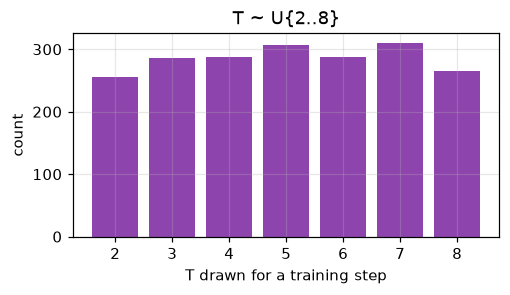

inference default T = 8 | effective depth = 10 layer applications


In [5]:
bb = build_backbone(tok.vocab_size, arch="looped", d_model=32, n_heads=4, n_layers=1, d_ff=64,
                    max_length=32, loop={"preset": "recurrent_depth"})
stack = bb.stack.train()
draws = Counter(stack.num_loops() for _ in range(2000))
plt.figure(figsize=(5, 2.4)); plt.bar(list(draws), list(draws.values()), color="#8e44ad")
plt.xlabel("T drawn for a training step"); plt.ylabel("count"); plt.title("T ~ U{2..8}"); plt.show()
stack.eval()
print("inference default T =", stack.num_loops(), "| effective depth =", stack.effective_depth, "layer applications")

## 5. Fixed point / DEQ (`deq_fixed_point`)

<img src="../../assets/looped/fixed_point.gif" width="100%">

Deep Equilibrium Models (Bai et al., 2019) ask for the **fixed point** $h^* = f_W(h^*, x)$ instead of a fixed
number of passes: iterate until $\|h_t - h_{t-1}\| / \|h_{t-1}\| <$ `exit_tolerance`, and backprop only
through the last pass (a one-step "phantom" gradient, `bptt_loops: 1`), so memory does not grow with depth.

A fixed point only exists if $f_W$ is **contractive**. We measured that our block is not, by default: the
per-pass change plateaus near 0.7. Adding post-norms (`sandwich_norm`) makes it contract geometrically - the
preset therefore turns them on.

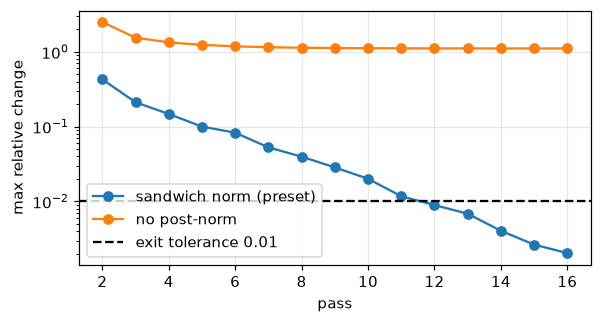

with exit_tolerance=0.01 the loop stopped after 12 of 16 passes


In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
for label, extra in (("sandwich norm (preset)", {}), ("no post-norm", {"sandwich_norm": False})):
    r = lab.train("deq_fixed_point", exit_tolerance=None, **extra)
    res = lab.trace(r).residuals()[1:]
    ax.semilogy(range(2, len(res) + 2), res, "o-", label=label)
ax.axhline(1e-2, color="k", ls="--", label="exit tolerance 0.01")
ax.set(xlabel="pass", ylabel="max relative change"); ax.legend(); plt.show()
r = lab.train("deq_fixed_point")
lab.trace(r)
print("with exit_tolerance=0.01 the loop stopped after", lab.stack(r).last_stats.loops, "of 16 passes")

## 6. Scratchpad memory (`scratchpad`)

<img src="../../assets/looped/scratchpad.gif" width="100%">

Four learned **memory tokens** are prepended inside the loop and dropped from the output: working memory
that persists across passes. Their attention is masked carefully - with causal attention every token may
read the slots, but the slots may only read each other (if a slot read token $j$, every earlier token would
see $j$ through it). The cell prints the actual mask the stack builds.

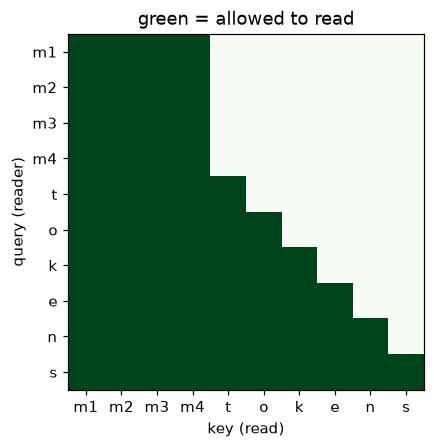

In [7]:
bb = build_backbone(tok.vocab_size, arch="looped", d_model=32, n_heads=4, n_layers=1, d_ff=64,
                    max_length=16, loop={"preset": "scratchpad"})
causal = torch.triu(torch.ones(6, 6, dtype=torch.bool), 1)
_, kw = bb.stack._prepend_scratch(torch.zeros(1, 6, 32), {"attn_mask": causal, "key_padding_mask": None,
                                                            "positions": torch.arange(6)})
names = ["m1", "m2", "m3", "m4"] + list("tokens")
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(~kw["attn_mask"], cmap="Greens")
ax.set_xticks(range(10), names); ax.set_yticks(range(10), names); ax.grid(False)
ax.set(xlabel="key (read)", ylabel="query (reader)", title="green = allowed to read"); plt.show()

## 7. Mixture-of-Recursions (`mixture_of_recursions`)

<img src="../../assets/looped/mixture_of_recursions.gif" width="100%">

Bae et al. (2025): a **router** decides each token's depth *up front*. Here it is the causal, token-choice
flavour: a linear router reads token $i$'s loop input $e_i$ once and picks $d_i \in \{1..T\}$; at pass $t$
only tokens with $d_i > t$ are updated, by a gated step

$$ h^i_t = h^i_{t-1} + g_i\,\big(\mathrm{Block}(h_{t-1})^i - h^i_{t-1}\big), \qquad g_i = \sigma(z_i[d_i]) . $$

The gate gives the router a gradient; a Switch-style **load-balancing loss**
$T \sum_d f_d P_d$ (fraction of tokens choosing depth $d$ times its mean probability) stops it from sending
everyone to the same depth. The preset keeps the first and last layer unshared (prelude/coda), like the paper.

```mermaid
flowchart LR
  E["e_i (each token)"] --> R["router: logits over depths 1..T"]
  R --> D["d_i = argmax · gate g_i"]
  D --> L["pass t updates only tokens with d_i > t"]
  L --> OUT["exited tokens keep their state"]
```

In [8]:
r = lab.train("mixture_of_recursions")
tr = lab.trace(r)
depth = tr.depth.tolist()
n, T = len(depth), max(depth)
print("granted depths:", sorted(Counter(depth).items()))
print(f"token-passes: {sum(depth)} of {n * T} ({1 - sum(depth) / (n * T):.0%} saved)")
print("router balance loss:", round(float(lab.stack(r).last_stats.router_balance), 3), "(1.0 = perfectly balanced)")
print("".join(f"{c}{d}" if c != " " else f"␣{d}" for c, d in zip(tr.text[:24], depth[:24])))

granted depths: [(1, 11), (2, 14), (3, 12), (4, 11)]
token-passes: 119 of 192 (38% saved)
router balance loss: 0.997 (1.0 = perfectly balanced)
t4h2e1␣4t1i2n3y2␣4m4o3d2e1l2␣4l2e1a4r2n3e1d1␣3t3


## 8. Relaxed recursion (`relaxed_recursive`)

<img src="../../assets/looped/relaxed_recursion.gif" width="100%">

Strict weight tying forces every pass to apply the identical map. Bae et al. (2024) relax it: every linear
layer of the core gets a small **per-pass LoRA delta**

$$ W_t = W + B_t A_t, \qquad A_t \in \mathbb{R}^{r \times d_{in}},\ B_t \in \mathbb{R}^{d_{out} \times r} . $$

$B_t$ starts at zero, so training begins from the exactly tied model, and the deltas cost
$T\,r\,(d_{in}+d_{out})$ parameters per layer. (PyTorch's fused `nn.MultiheadAttention` never calls its
projections, so with `attn_impl: mha` only the MLP is relaxed; `gqa` / `mqa` relax attention too.)

In [9]:
r = lab.train("relaxed_recursive")
wrapped = [m for m in lab.stack(r).core.modules() if isinstance(m, LoopLoRALinear)]
base = sum(m.weight.numel() for m in wrapped)
extra = sum(m.down.numel() + m.up.numel() for m in wrapped)
print(f"{len(wrapped)} relaxed linear layers: shared {base:,} params + per-pass deltas {extra:,}")
for t in range(wrapped[0].down.shape[0]):
    rel = [float(m.delta_weight(t).detach().norm() / m.weight.detach().norm()) for m in wrapped]
    print(f"pass {t + 1}: |ΔW|/|W| = " + ", ".join(f"{x:.1%}" for x in rel))

2 relaxed linear layers: shared 16,384 params + per-pass deltas 6,144
pass 1: |ΔW|/|W| = 24.8%, 24.7%
pass 2: |ΔW|/|W| = 13.8%, 11.9%
pass 3: |ΔW|/|W| = 8.6%, 10.6%
pass 4: |ΔW|/|W| = 11.2%, 10.8%


## 9. Sharing schedules (`sequence_sharing`, `cycle_rev_sharing`)

<img src="../../assets/looped/sharing_patterns.gif" width="100%">

With a core of several layers, *in which order* should the passes use them? Takase & Kiyono (2021) compare
**cycle** (AB AB …, the default), **cycle (rev)** (AB BA …) and **sequence** (AA … BB …). Same parameters,
different computation. `LoopedStack.pass_layers` builds the schedule:

In [10]:
for sharing in ("cycle", "cycle_rev", "sequence"):
    bb = build_backbone(tok.vocab_size, arch="looped", d_model=32, n_heads=4, n_layers=2, d_ff=64,
                        max_length=16, loop={"n_loops": 4, "sharing": sharing})
    names = {id(layer): "AB"[i] for i, layer in enumerate(bb.stack.core)}
    order = " ".join("".join(names[id(m)] for m in bb.stack.pass_layers(t, 4)) for t in range(4))
    print(f"{sharing:10s} {order}")

cycle      AB AB AB AB
cycle_rev  AB BA AB BA
sequence   AA AA BB BB


## 10. All variants on the same real text

Every variant (plus a 1-block and a 4-block stacked baseline) trains a character LM on the library's
docstrings for 1200 AdamW steps (width 64, CPU) and is scored by **held-out bits per character**. "Layer
applications" is the compute depth per token at the default loop count. This takes ~10 minutes.

In [11]:
import time

rows = []
def bench(label, model, variant="looped", applications=None):
    t0 = time.time()
    r = lab.train_text(model, variant=variant, steps=1200)
    rows.append((label, sum(p.numel() for p in r.model.parameters()), applications, lab.text_loss(r),
                 time.time() - t0))

bench("stacked 1 layer", {"arch": "transformer", "n_layers": 1}, "autoregressive", 1)
bench("stacked 4 layers", {"arch": "transformer", "n_layers": 4}, "autoregressive", 4)
for name in LOOP_PRESETS:
    spec = LoopSpec.preset_spec(name)
    n_layers = 2 if spec.sharing != "cycle" else 1
    bench(name, {"arch": "looped", "n_layers": n_layers, "loop": {"preset": name}},
          applications=spec.prelude_layers + spec.n_loops * n_layers + spec.coda_layers)

print(f"{'model':28s} {'params':>8s} {'layer apps':>10s} {'val bits/char':>14s} {'train s':>8s}")
for label, params, apps, bpc, sec in sorted(rows, key=lambda r: r[3]):
    print(f"{label:28s} {params / 1e3:7.1f}k {apps!s:>10s} {bpc:14.3f} {sec:8.0f}")

model                          params layer apps  val bits/char  train s
recurrent_depth                119.2k         10          2.846       69
stacked 4 layers               144.4k          4          2.892       27
sequence_sharing                77.4k          8          2.918       90
mixture_of_recursions          111.3k          6          2.948       62
cycle_rev_sharing               77.4k          8          3.104       99
universal_transformer_act       44.0k          8          3.384       76
universal_transformer           44.0k          6          3.399       51
deq_fixed_point                 52.3k         16          3.414       69
scratchpad                      44.2k          6          3.463       78
relaxed_recursive               50.1k          4          3.493       46
stacked 1 layer                 44.0k          1          3.737       14
input_injection                 44.0k          6          4.140       51


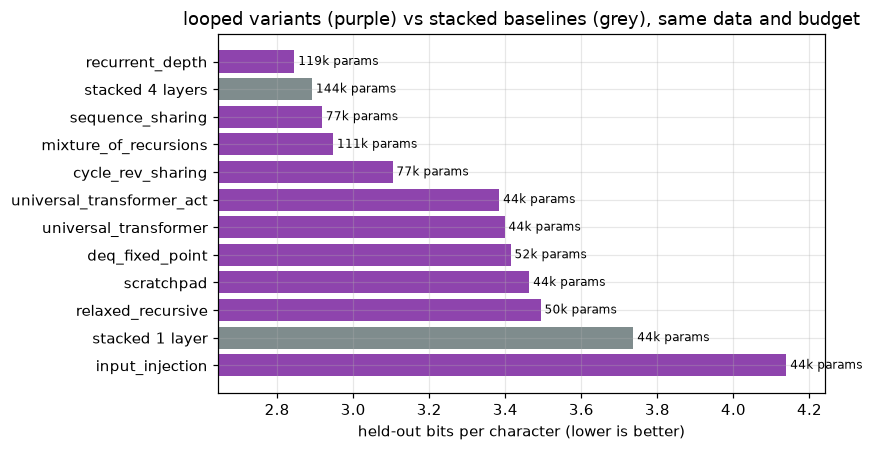

In [12]:
rs = sorted(rows, key=lambda r: r[3])
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ["#7f8c8d" if r[0].startswith("stacked") else "#8e44ad" for r in rs]
ax.barh([r[0] for r in rs], [r[3] for r in rs], color=colors)
ax.invert_yaxis(); ax.set_xlim(min(r[3] for r in rs) - 0.2, max(r[3] for r in rs) + 0.1)
for i, r in enumerate(rs):
    ax.text(r[3] + 0.01, i, f"{r[1] / 1e3:.0f}k params", va="center", fontsize=8)
ax.set_xlabel("held-out bits per character (lower is better)")
ax.set_title("looped variants (purple) vs stacked baselines (grey), same data and budget")
plt.tight_layout(); plt.show()

## What the comparison says

The executed run above (1200 steps, seed 0, CPU) is summarised below. An earlier identical run is shown
alongside: CPU kernels are not bit-deterministic across runs, and the spread is part of the result.

| | params | this run | earlier run |
|---|---|---|---|
| `recurrent_depth` | 119k | **2.85** | 2.87 |
| stacked 4 layers | 144k | 2.89 | 3.08 |
| `sequence_sharing` (2-layer core) | 77k | 2.92 | 2.92 |
| `mixture_of_recursions` | 111k | 2.95 | 2.95 |
| `cycle_rev_sharing` (2-layer core) | 77k | 3.10 | 3.10 |
| `universal_transformer_act` / `universal_transformer` | 44k | 3.38 / 3.40 | 3.37 / 3.38 |
| `deq_fixed_point` / `scratchpad` / `relaxed_recursive` | 44-52k | 3.41 / 3.46 / 3.49 | 3.40 / 3.45 / 3.46 |
| stacked 1 layer | 44k | 3.74 | 3.75 |
| `input_injection` (plain `add`) | 44k | 4.14 | 4.13 |

* **Looping one block helps at equal parameters, robustly.** In both runs every 44-52k looped variant beats
  the 1-layer stacked model with the same parameters (about 3.4-3.5 vs 3.74). The exception is plain `add`
  injection (4.14), whose inflating residual stream notebook 01 diagnosed.
* **`recurrent_depth` was best in both runs** (prelude + core + coda: 3 distinct layers run 10 deep). It beat 4
  stacked layers with 82% of their parameters.
* **`sequence_sharing` (77k) and `mixture_of_recursions` (111k) land right next to 4 stacked layers (144k).**
  The stacked baseline itself moved by 0.19 bits between runs (2.89 vs 3.08), so these are ties within
  run-to-run noise, not wins.
* **Order matters for a shared 2-layer core.** `sequence` (AA BB) beat `cycle_rev` (AB BA) by about 0.18 bits
  in both runs, with identical parameters.
* **Smaller differences.** ACT matched the fixed loop. Relaxed recursion's small per-pass deltas did not help
  at this scale. The DEQ recipe trades a little quality for O(1) training memory (one-step gradient). The
  router's compute saving was measured on the toy corpus (§7: 38% of token-passes skipped).

These are single-seed, width-64 models on about 430k characters: they show what each variant does and
roughly how they rank, not how they would rank at scale. Before drawing firm conclusions, run several seeds
(`LoopLab(seed=...)`) and more steps (`steps=`), and set `torch.use_deterministic_algorithms(True)` for exact
reruns.

**Recap: every knob is a `LoopSpec` field or a preset.**
`loop: {preset: <name>, <overrides>}` in YAML, or `LoopSpec.preset_spec(name, ...)` in Python. Notebook 01
explains the base machinery; `docs/looped.md` lists every option.